## Fine-tuning Stable Diffusion XL with DreamBooth and LoRA on a free-tier Colab Notebook 🧨

In this notebook, we show how to fine-tune [Stable Diffusion XL (SDXL)](https://huggingface.co/docs/diffusers/main/en/api/pipelines/stable_diffusion/stable_diffusion_xl) with [DreamBooth](https://huggingface.co/docs/diffusers/main/en/training/dreambooth) and [LoRA](https://huggingface.co/docs/diffusers/main/en/training/lora) on a T4 GPU.

SDXL consists of a much larger UNet and two text encoders that make the cross-attention context quite larger than the previous variants.

So, to pull this off, we will make use of several tricks such as gradient checkpointing, mixed-precision, and 8-bit Adam. So, hang tight and let's get started 🧪

## Setup 🪓

In [5]:
# Check the GPU
!nvidia-smi

/bin/bash: line 1: nvidia-smi: command not found


In [6]:
# Install dependencies.
!pip install bitsandbytes transformers accelerate peft -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 10.2 MB/s eta 0:00:00


In [7]:
!pip install --upgrade torchao

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 10.7 MB/s eta 0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0


Make sure to install `diffusers` from `main`.

In [8]:
!pip install git+https://github.com/huggingface/diffusers.git -q

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


Download diffusers SDXL DreamBooth training script.

In [9]:
!wget https://raw.githubusercontent.com/huggingface/diffusers/main/examples/dreambooth/train_dreambooth_lora_sdxl.py

--2026-10-17 18:54:54--  https://raw.githubusercontent.com/huggingface/diffusers/main/examples/dreambooth/train_dreambooth_lora_sdxl.py
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.110.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 86933 (85K) [text/plain]
Saving to: ‘train_dreambooth_lora_sdxl.py.1’

train_dreambooth_lo 100%[===================>]  84.90K  --.-KB/s    in 0.05s   

2026-10-17 18:54:54 (1.76 MB/s) - ‘train_dreambooth_lora_sdxl.py.1’ saved [86933/86933]



## Dataset 🐶

**Let's get our training data!**
For this example, we'll download some images from the hub

If you already have a dataset on the hub you wish to use, you can skip this part and go straight to: "Prep for
training 💻" section, where you'll simply specify the dataset name.

If your images are saved locally, and/or you want to add BLIP generated captions,
upload the file through the cell below, or upload them manually to specified directory.



In [10]:
import os

local_dir = "./cher/" #@param
os.makedirs(local_dir,exist_ok=True)

**Upload** example images from your local files. You can also upload your images manually to the speficied folder.

In [11]:
from google.colab import files

# pick a name for the image folder
os.chdir(local_dir)

# choose and upload local images into the newly created directory
uploaded_images = files.upload()
os.chdir("/content") # back to parent directory

Saving 001.png to 001.png
Saving 002.png to 002.png
Saving 003.png to 003.png
Saving 004.png to 004.png
Saving 005.png to 005.png
Saving 006.png to 006.png
Saving 007.png to 007.png
Saving 008.png to 008.png
Saving 009.png to 009.png
Saving 010.png to 010.png
Saving 011.png to 011.png
Saving 012.png to 012.png
Saving 013.png to 013.png
Saving 014.png to 014.png
Saving 015.png to 015.png
Saving 016.png to 016.png
Saving 017.png to 017.png
Saving 018.png to 018.png
Saving 019.png to 019.png
Saving 020.png to 020.png
Saving 021.png to 021.png
Saving 022.png to 022.png
Saving 023.png to 023.png
Saving 024.png to 024.png
Saving 025.png to 025.png
Saving 026.png to 026.png
Saving 027.png to 027.png
Saving 028.png to 028.png
Saving 029.png to 029.png
Saving 030.png to 030.png
Saving 031.png to 031.png
Saving 032.png to 032.png
Saving 033.png to 033.png
Saving 034.png to 034.png
Saving 035.png to 035.png
Saving 036.png to 036.png
Saving 037.png to 037.png
Saving 038.png to 038.png
Saving 039.p

Preview the images:

In [12]:
from PIL import Image

def image_grid(imgs, rows, cols, resize=256):

    if resize is not None:
        imgs = [img.resize((resize, resize)) for img in imgs]
    w, h = imgs[0].size
    grid = Image.new("RGB", size=(cols * w, rows * h))
    grid_w, grid_h = grid.size

    for i, img in enumerate(imgs):
        grid.paste(img, box=(i % cols * w, i // cols * h))
    return grid

Найдено фотографий: 50


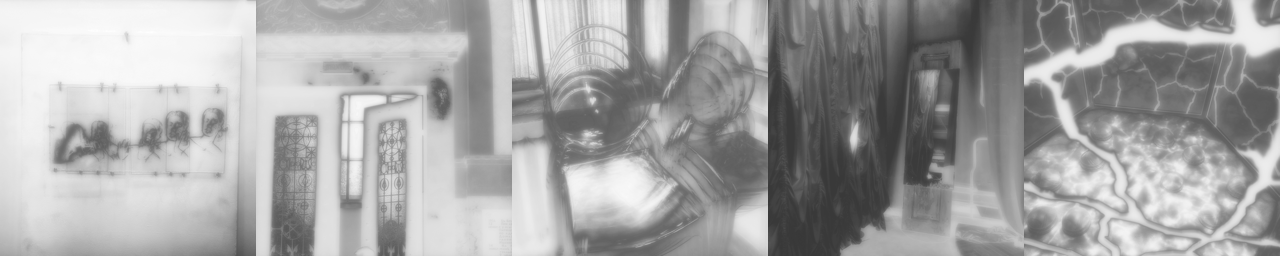

In [13]:
import glob
import os
from PIL import Image

img_paths = [
    path for path in glob.glob(os.path.join(local_dir, "*"))
    if path.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Найдено фотографий:", len(img_paths))

imgs = [Image.open(path).convert("RGB") for path in img_paths]

num_imgs_to_preview = min(5, len(imgs))

if num_imgs_to_preview > 0:
    display(image_grid(imgs[:num_imgs_to_preview], 1, num_imgs_to_preview))
else:
    print("Фотографии не найдены. Проверь папку:", local_dir)

### Generate custom captions with BLIP
Load BLIP to auto caption your images:

In [14]:
import requests
from transformers import AutoProcessor, BlipForConditionalGeneration
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"

# load the processor and the captioning model
blip_processor = AutoProcessor.from_pretrained("Salesforce/blip-image-captioning-base")
blip_model = BlipForConditionalGeneration.from_pretrained("Salesforce/blip-image-captioning-base",torch_dtype=torch.float16).to(device)

# captioning utility
def caption_images(input_image):
    inputs = blip_processor(images=input_image, return_tensors="pt").to(device, torch.float16)
    pixel_values = inputs.pixel_values

    generated_ids = blip_model.generate(pixel_values=pixel_values, max_length=50)
    generated_caption = blip_processor.batch_decode(generated_ids, skip_special_tokens=True)[0]
    return generated_caption

preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.56k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/506 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  990MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

In [15]:
import glob
from PIL import Image

# create a list of (Pil.Image, path) pairs
local_dir = "./cher/"
imgs_and_paths = [
    (path, Image.open(path).convert("RGB"))
    for path in glob.glob(f"{local_dir}*")
    if path.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Фотографий для BLIP:", len(imgs_and_paths))

Фотографий для BLIP: 50


Now let's add the concept token identifier (e.g. TOK) to each caption using a caption prefix.
Feel free to change the prefix according to the concept you're training on!
- for this example we can use "a photo of TOK," other options include:
    - For styles - "In the style of TOK"
    - For faces - "photo of a TOK person"
- You can add additional identifiers to the prefix that can help steer the model in the right direction.
-- e.g. for this example, instead of "a photo of TOK" we can use "a photo of TOK dog" / "a photo of TOK corgi dog"

In [16]:
import json

caption_prefix = "in the style of siaxmono, " #@param
with open(f'{local_dir}metadata.jsonl', 'w') as outfile:
  for img in imgs_and_paths:
      caption = caption_prefix + caption_images(img[1]).split("\n")[0]
      entry = {"file_name":img[0].split("/")[-1], "prompt": caption}
      json.dump(entry, outfile)
      outfile.write('\n')

In [17]:
!cat cher/metadata.jsonl

{"file_name": "009.png", "prompt": "in the style of siaxmono, a black and white photo of a wall with a painting on it"}
{"file_name": "029.png", "prompt": "in the style of siaxmono, a black and white photo of a door"}
{"file_name": "037.png", "prompt": "in the style of siaxmono, a chair sitting in front of a window"}
{"file_name": "019.png", "prompt": "in the style of siaxmono, a room with a mirror and a curtain"}
{"file_name": "047.png", "prompt": "in the style of siaxmono, a black and white image of a floor"}
{"file_name": "023.png", "prompt": "in the style of siaxmono, a bench on the beach with a lot of sand"}
{"file_name": "031.png", "prompt": "in the style of siaxmono, a black and white photo of a room with a ceiling"}
{"file_name": "025.png", "prompt": "in the style of siaxmono, a clock is shown in the reflection of a tree"}
{"file_name": "026.png", "prompt": "in the style of siaxmono, a tiled floor with a tile pattern"}
{"file_name": "001.png", "prompt": "in the style of siaxmon

Free some memory:

In [18]:
import gc

# delete the BLIP pipelines and free up some memory
del blip_processor, blip_model
gc.collect()
torch.cuda.empty_cache()

## Prep for training 💻

Initialize `accelerate`:

In [19]:
import locale
locale.getpreferredencoding = lambda: "UTF-8"

!accelerate config default

accelerate configuration saved at /root/.cache/huggingface/accelerate/default_config.yaml


### Log into your Hugging Face account
Pass [your **write** access token](https://huggingface.co/settings/tokens) so that we can push the trained checkpoints to the Hugging Face Hub:

In [20]:
from huggingface_hub import notebook_login
notebook_login()

## Train! 🔬

#### Set Hyperparameters ⚡
To ensure we can DreamBooth with LoRA on a heavy pipeline like Stable Diffusion XL, we're using:

* Gradient checkpointing (`--gradient_accumulation_steps`)
* 8-bit Adam (`--use_8bit_adam`)
* Mixed-precision training (`--mixed-precision="fp16"`)

### Launch training 🚀🚀🚀

To allow for custom captions we need to install the `datasets` library, you can skip that if you want to train solely
 with `--instance_prompt`.
In that case, specify `--instance_data_dir` instead of `--dataset_name`

In [21]:
!pip install datasets -q

 - Use `--output_dir` to specify your LoRA model repository name!
 - Use `--caption_column` to specify name of the cpation column in your dataset. In this example we used "prompt" to
 save our captions in the
 metadata file, change this according to your needs.

In [22]:
%cd /content

!wget -O train_dreambooth_lora_sdxl.py https://raw.githubusercontent.com/huggingface/diffusers/main/examples/dreambooth/train_dreambooth_lora_sdxl.py

!ls -lh train_dreambooth_lora_sdxl.py

/content
--2026-10-17 19:56:16--  https://raw.githubusercontent.com/huggingface/diffusers/main/examples/dreambooth/train_dreambooth_lora_sdxl.py
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 86933 (85K) [text/plain]
Saving to: ‘train_dreambooth_lora_sdxl.py’

train_dreambooth_lo 100%[===================>]  84.90K  --.-KB/s    in 0.05s   

2026-10-17 19:56:16 (1.82 MB/s) - ‘train_dreambooth_lora_sdxl.py’ saved [86933/86933]

-rw-r--r-- 1 root root 85K Oct 17 19:56 train_dreambooth_lora_sdxl.py


In [23]:
#!/usr/bin/env bash
!accelerate launch train_dreambooth_lora_sdxl.py \
  --pretrained_model_name_or_path="stabilityai/stable-diffusion-xl-base-1.0" \
  --pretrained_vae_model_name_or_path="madebyollin/sdxl-vae-fp16-fix" \
  --dataset_name="cher" \
  --output_dir="siaxmono_style_LoRA" \
  --caption_column="prompt"\
  --mixed_precision="fp16" \
  --instance_prompt="in the style of siaxmono" \
  --resolution=768 \
  --rank=32 \
  --train_batch_size=1 \
  --gradient_accumulation_steps=3 \
  --gradient_checkpointing \
  --learning_rate=1e-4 \
  --snr_gamma=5.0 \
  --lr_scheduler="constant" \
  --lr_warmup_steps=0 \
  --mixed_precision="fp16" \
  --use_8bit_adam \
  --max_train_steps=1000 \
  --checkpointing_steps=250 \
  --seed="0"

Failed to load /usr/local/lib/python3.13/dist-packages/torchao/_C_cutlass_90a.abi3.so: Could not load this library: /usr/local/lib/python3.13/dist-packages/torchao/_C_cutlass_90a.abi3.so
Failed to load /usr/local/lib/python3.13/dist-packages/torchao/_C_mxfp8.cpython-310-x86_64-linux-gnu.so: Could not load this library: /usr/local/lib/python3.13/dist-packages/torchao/_C_mxfp8.cpython-310-x86_64-linux-gnu.so
Unable to import `torchao` Tensor objects. This may affect loading checkpoints serialized with `torchao`
10/17/2026 19:57:00 - INFO - __main__ - [RANK 0] Distributed environment: DistributedType.NO
Num processes: 1
Process index: 0
Local process index: 0
Device: cpu

Mixed precision type: fp16

10/17/2026 19:57:01 - INFO - httpx - HTTP Request: GET https://huggingface.co/api/models/stabilityai/stable-diffusion-xl-base-1.0 "HTTP/1.1 200 OK"
10/17/2026 19:57:01 - INFO - httpx - HTTP Request: HEAD https://huggingface.co/stabilityai/stable-diffusion-xl-base-1.0/resolve/462165984030d82259

In [27]:

import torch

print("CUDA доступна:", torch.cuda.is_available())
print("Видеокарта:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Не обнаружена")
print("Версия PyTorch:", torch.__version__)


CUDA доступна: False
Видеокарта: Не обнаружена
Версия PyTorch: 2.11.0+cpu


In [24]:
!ls cherakshin_style_LoRA

ls: cannot access 'cherakshin_style_LoRA': No such file or directory


In [26]:

import os

for root, dirs, files in os.walk("/content"):
    for name in dirs:
        if name.startswith("checkpoint-"):
            print("Checkpoint:", os.path.join(root, name))
    for name in files:
        if name.endswith(".safetensors"):
            print("Модель:", os.path.join(root, name))


### Save your model to the hub and check it out 🔥

In [ ]:
from huggingface_hub import whoami
from pathlib import Path
#@markdown make sure the `output_dir` you specify here is the same as the one used for training
output_dir = "cherakshin_style_LoRA" #@param
username = whoami(token=Path("/root/.cache/huggingface/"))["name"]
repo_id = f"{username}/{output_dir}"

In [ ]:
# @markdown Sometimes training finishes succesfuly (i.e. a **.safetensores** file with the LoRA weights saved properly to your local `output_dir`) but there's not enough RAM in the free tier to push the model to the hub 🙁
# @markdown
# @markdown To mitigate this, run this cell with your training arguments to make sure your model is uploaded! 🤗

# push to the hub🔥
from train_dreambooth_lora_sdxl import save_model_card
from huggingface_hub import upload_folder, create_repo

repo_id = create_repo(repo_id, exist_ok=True).repo_id

# change the params below according to your training arguments
save_model_card(
    repo_id = repo_id,
    images=[],
    base_model="stabilityai/stable-diffusion-xl-base-1.0",
    train_text_encoder=False,
    instance_prompt="photo collage in CHERKASHIN style",
    validation_prompt=None,
    repo_folder=output_dir,
    use_dora = False,
    vae_path="madebyollin/sdxl-vae-fp16-fix",
)

upload_folder(
    repo_id=repo_id,
    folder_path=output_dir,
    commit_message="End of training",
    ignore_patterns=["step_*", "epoch_*"],
)

In [ ]:
from IPython.display import display, Markdown

link_to_model = f"https://huggingface.co/{repo_id}"
display(Markdown("### Your model has finished training.\nAccess it here: {}".format(link_to_model)))

Let's generate some images with it!

## Inference 🐕

In [ ]:
import torch
from diffusers import DiffusionPipeline, AutoencoderKL

vae = AutoencoderKL.from_pretrained("madebyollin/sdxl-vae-fp16-fix", torch_dtype=torch.float16)
pipe = DiffusionPipeline.from_pretrained(
    "stabilityai/stable-diffusion-xl-base-1.0",
    vae=vae,
    torch_dtype=torch.float16,
    variant="fp16",
    use_safetensors=True
)
pipe.load_lora_weights(repo_id)
_ = pipe.to("cuda")

In [ ]:
prompt = "photo collage in CHERKASHIN style, times square, new york" # @param

image = pipe(prompt=prompt, num_inference_steps=25).images[0]
image

In [ ]:
vae = AutoencoderKL.from_pretrained("madebyollin/sdxl-vae-fp16-fix", torch_dtype=torch.float16)
pipe = DiffusionPipeline.from_pretrained(
    "stabilityai/stable-diffusion-xl-base-1.0",
    vae=vae,
    torch_dtype=torch.float16,
    variant="fp16",
    use_safetensors=True
)
pipe.load_lora_weights("cherakshin_style_LoRA/checkpoint-250")
pipe.fuse_lora(lora_scale=0.5)
_ = pipe.to("cuda")

In [ ]:
prompt = "photo collage in CHERKASHIN style, times square, new york" # @param

image = pipe(prompt=prompt, num_inference_steps=25).images[0]
image